# Caderno de Estudo e Simulação: Verificação Numérica de Gradientes (Gradient Checking)

> **Objetivo:** Este caderno serve como laboratório analítico e visual para dissecar a técnica de verificação numérica de gradientes (*Gradient Checking*). Demonstramos geometricamente a superioridade da diferença centrada sobre a unilateral, a curva em 'V' do compromisso entre truncamento e cancelamento catastrófico, e executamos a auditoria completa de todas as ativações, camadas densas e redes neurais profundas da biblioteca.
>
> **Nota de uso:** Destinado ao estudo individual e preparação para a arguição oral da disciplina de Aprendizado de Máquinas (INE5664 - UFSC).


In [1]:
import sys
from pathlib import Path

# Configuração do caminho raiz do projeto
raiz_projeto = Path.cwd().resolve()
while raiz_projeto.name != "projeto-final-mlp" and raiz_projeto.parent != raiz_projeto:
    raiz_projeto = raiz_projeto.parent
if str(raiz_projeto) not in sys.path:
    sys.path.insert(0, str(raiz_projeto))

import numpy as np
import matplotlib
import matplotlib.pyplot as plt

# Estilização visual dos gráficos
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.size"] = 10
plt.rcParams["figure.dpi"] = 120

from mlp.checagem_gradientes import (
    calcular_erro_relativo,
    checar_gradiente_ativacao,
    checar_gradiente_camada_densa,
    checar_gradiente_rede
)
from mlp.camadas import Densa
from mlp.ativacoes import (
    Sigmoide, LeakyReLU, Swish, Softmax, Tanh, ELU, Softplus, Softsign
)
from mlp.custos import MSE, BCE, CCE
from mlp.rede import RedeNeural

print("Ambiente configurado com sucesso!")
print(f"NumPy versão: {np.__version__}")
print(f"Raiz do projeto: {raiz_projeto}")


Ambiente configurado com sucesso!
NumPy versão: 1.26.4
Raiz do projeto: /home/luizeduardo/_dev/faculdade/aprendizado_maquinas/projeto-final-mlp


## 1. Intuição Geométrica: Diferença Unilateral vs. Diferença Centrada

A derivada de uma função em um ponto $\theta$ é o coeficiente angular da reta tangente naquele ponto:

$$f'(\theta) = \lim_{\epsilon \to 0} \frac{f(\theta + \epsilon) - f(\theta)}{\epsilon}$$

Numericamente, não podemos fazer $\epsilon \to 0$. Ao escolher um $\epsilon$ finito, aproximamos a reta tangente por uma reta secante.

### As Duas Abordagens:
1. **Diferença Unilateral (*Forward Difference*):**
   $$\frac{f(\theta + \epsilon) - f(\theta)}{\epsilon} = f'(\theta) + \mathcal{O}(\epsilon)$$
   - Erro de aproximação de **primeira ordem** $\mathcal{O}(\epsilon)$.
2. **Diferença Centrada (*Central Difference*):**
   $$\frac{f(\theta + \epsilon) - f(\theta - \epsilon)}{2\epsilon} = f'(\theta) + \mathcal{O}(\epsilon^2)$$
   - Erro de aproximação de **segunda ordem** $\mathcal{O}(\epsilon^2)$.

Abaixo, ilustramos geometricamente as duas aproximações em uma função não-linear.


Derivada Exata:            1.000000
Diferença Centrada (O(eps^2)): 1.490000 | Erro: 0.4900
Diferença Unilateral (O(eps)): 3.590000 | Erro: 2.5900


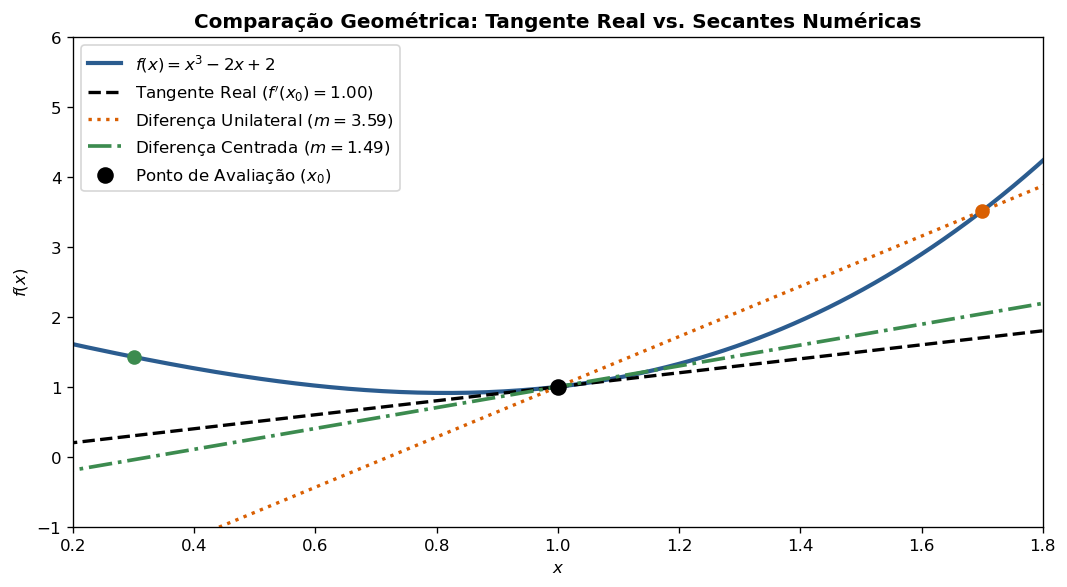

In [2]:
# Ilustração geométrica da aproximação por diferenças finitas
def f(x):
    return x ** 3 - 2 * x + 2

def df(x):
    return 3 * x ** 2 - 2

x0 = 1.0
eps_demo = 0.7  # Epsilon propositalmente visível para demonstração geométrica

x_vals = np.linspace(0.1, 2.0, 200)
y_vals = f(x_vals)

fig, ax = plt.subplots(figsize=(9, 5))

# Curva da função f(x)
ax.plot(x_vals, y_vals, color="#2b5c8f", linewidth=2.5, label="$f(x) = x^3 - 2x + 2$")

# 1. Reta Tangente Real (Derivada analítica exata)
m_real = df(x0)
y_tangente = f(x0) + m_real * (x_vals - x0)
ax.plot(x_vals, y_tangente, color="black", linestyle="--", linewidth=2.0, label=f"Tangente Real ($f'(x_0)={m_real:.2f}$)")

# 2. Secante Unilateral: (f(x0 + eps) - f(x0)) / eps
m_unilateral = (f(x0 + eps_demo) - f(x0)) / eps_demo
y_sec_uni = f(x0) + m_unilateral * (x_vals - x0)
ax.plot(x_vals, y_sec_uni, color="#d95f02", linestyle=":", linewidth=2.0, label=f"Diferença Unilateral ($m={m_unilateral:.2f}$)")

# 3. Secante Centrada: (f(x0 + eps) - f(x0 - eps)) / (2 * eps)
m_centrada = (f(x0 + eps_demo) - f(x0 - eps_demo)) / (2 * eps_demo)
y_sec_cent = f(x0) + m_centrada * (x_vals - x0)
ax.plot(x_vals, y_sec_cent, color="#3c8b4f", linestyle="-.", linewidth=2.2, label=f"Diferença Centrada ($m={m_centrada:.2f}$)")

# Pontos de avaliação
ax.scatter([x0], [f(x0)], color="black", s=80, zorder=5, label="Ponto de Avaliação $(x_0)$")
ax.scatter([x0 + eps_demo], [f(x0 + eps_demo)], color="#d95f02", s=60, zorder=5)
ax.scatter([x0 - eps_demo], [f(x0 - eps_demo)], color="#3c8b4f", s=60, zorder=5)

ax.set_title("Comparação Geométrica: Tangente Real vs. Secantes Numéricas", fontweight="bold")
ax.set_xlabel("$x$")
ax.set_ylabel("$f(x)$")
ax.set_xlim(0.2, 1.8)
ax.set_ylim(-1, 6)
ax.legend(loc="upper left", fontsize=10)

plt.tight_layout()
plt.show()

print(f"Derivada Exata:            {m_real:.6f}")
print(f"Diferença Centrada (O(eps^2)): {m_centrada:.6f} | Erro: {abs(m_centrada - m_real):.4f}")
print(f"Diferença Unilateral (O(eps)): {m_unilateral:.6f} | Erro: {abs(m_unilateral - m_real):.4f}")


## 2. A Curva em 'V': O Dilema entre Truncamento e Cancelamento Catastrófico

Por que não utilizamos $\epsilon = 10^{-20}$ para aproximar a derivada?

Em ponto flutuante de precisão dupla (64 bits):
1. **Para $\epsilon$ grande ($> 10^{-4}$):** o erro é dominado pelo **erro de truncamento** da Série de Taylor (proporcional a $\epsilon^2$).
2. **Para $\epsilon$ excessivamente pequeno ($< 10^{-10}$):** $f(x + \epsilon)$ e $f(x - \epsilon)$ tornam-se tão próximos que seus dígitos mais significativos se cancelam na subtração (**cancelamento catastrófico**). A divisão por $2\epsilon$ amplifica o ruído de arredondamento.

O gráfico abaixo varre $\epsilon$ de $10^{-15}$ até $10^{-1}$, evidenciando o ponto ótimo de mínimo erro em torno de $\epsilon \approx 10^{-7}$.


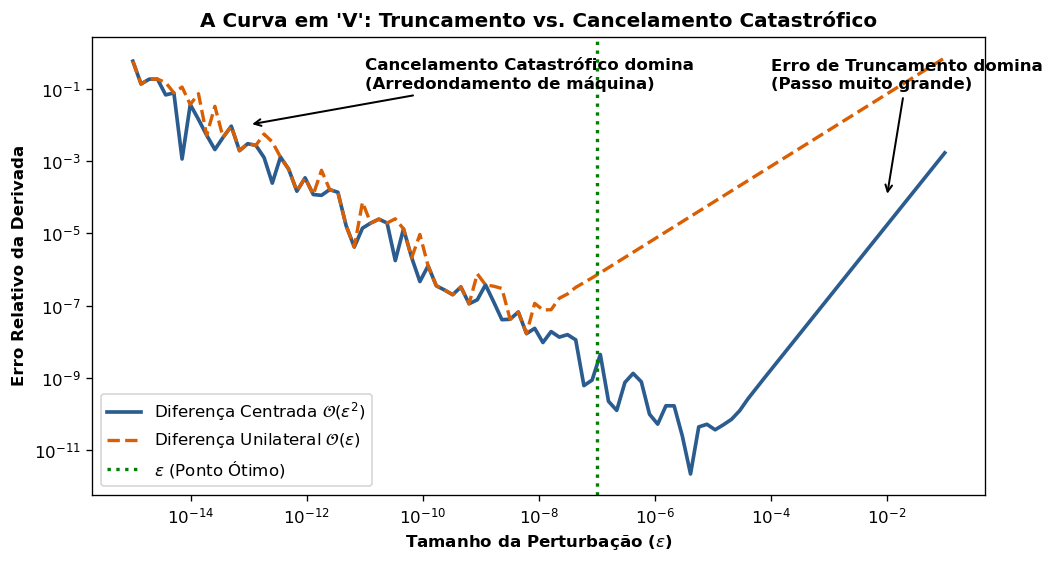

In [3]:
# Varredura do comportamento do erro numérico em função de epsilon
epsilons = np.logspace(-15, -1, 100)
erros_centrada = []
erros_unilateral = []

x_teste = 1.5
derivada_exata = np.cos(x_teste)  # f(x) = sin(x) -> f'(x) = cos(x)

for eps in epsilons:
    # Diferença centrada
    aprox_centrada = (np.sin(x_teste + eps) - np.sin(x_teste - eps)) / (2.0 * eps)
    err_c = abs(aprox_centrada - derivada_exata) / abs(derivada_exata)
    erros_centrada.append(err_c)
    
    # Diferença unilateral
    aprox_unilateral = (np.sin(x_teste + eps) - np.sin(x_teste)) / eps
    err_u = abs(aprox_unilateral - derivada_exata) / abs(derivada_exata)
    erros_unilateral.append(err_u)

fig, ax = plt.subplots(figsize=(9, 4.8))

ax.plot(epsilons, erros_centrada, label="Diferença Centrada $\mathcal{O}(\epsilon^2)$", color="#2b5c8f", linewidth=2.2)
ax.plot(epsilons, erros_unilateral, label="Diferença Unilateral $\mathcal{O}(\epsilon)$", color="#d95f02", linewidth=2.0, linestyle="--")

# Destaca o ponto ideal (epsilon = 1e-7)
ax.axvline(1e-7, color="green", linestyle=":", linewidth=2, label="$\epsilon \approx 10^{-7}$ (Ponto Ótimo)")

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_title("A Curva em 'V': Truncamento vs. Cancelamento Catastrófico", fontweight="bold")
ax.set_xlabel("Tamanho da Perturbação ($\epsilon$)", fontweight="bold")
ax.set_ylabel("Erro Relativo da Derivada", fontweight="bold")
ax.legend(fontsize=10)

ax.annotate("Erro de Truncamento domina\n(Passo muito grande)", xy=(1e-2, 1e-4), xytext=(1e-4, 1e-1),
            arrowprops=dict(facecolor='black', arrowstyle='->', lw=1.2), fontweight="bold")

ax.annotate("Cancelamento Catastrófico domina\n(Arredondamento de máquina)", xy=(1e-13, 1e-2), xytext=(1e-11, 1e-1),
            arrowprops=dict(facecolor='black', arrowstyle='->', lw=1.2), fontweight="bold")

plt.tight_layout()
plt.show()


## 3. Auditoria Completa das 8 Funções de Ativação

Abaixo, executamos a verificação numérica automatizada contra todas as 8 funções de ativação implementadas no módulo `mlp/ativacoes.py`:
1. `Sigmoide`
2. `LeakyReLU`
3. `Swish`
4. `Softmax`
5. `Tanh`
6. `ELU`
7. `Softplus`
8. `Softsign`

Todas são avaliadas utilizando o limiar rigoroso de tolerância relativa $< 10^{-6}$.


--- RELATÓRIO DE AUDITORIA DAS ATIVAÇÕES ---
Sigmoide     -> Erro Relativo: 5.39e-09 | Status: APROVADO (< 1e-6)
LeakyReLU    -> Erro Relativo: 1.23e-09 | Status: APROVADO (< 1e-6)
Swish        -> Erro Relativo: 1.62e-09 | Status: APROVADO (< 1e-6)
Softmax      -> Erro Relativo: 2.66e-09 | Status: APROVADO (< 1e-6)
Tanh         -> Erro Relativo: 1.63e-09 | Status: APROVADO (< 1e-6)
ELU          -> Erro Relativo: 1.23e-09 | Status: APROVADO (< 1e-6)
Softplus     -> Erro Relativo: 2.39e-09 | Status: APROVADO (< 1e-6)
Softsign     -> Erro Relativo: 1.41e-09 | Status: APROVADO (< 1e-6)


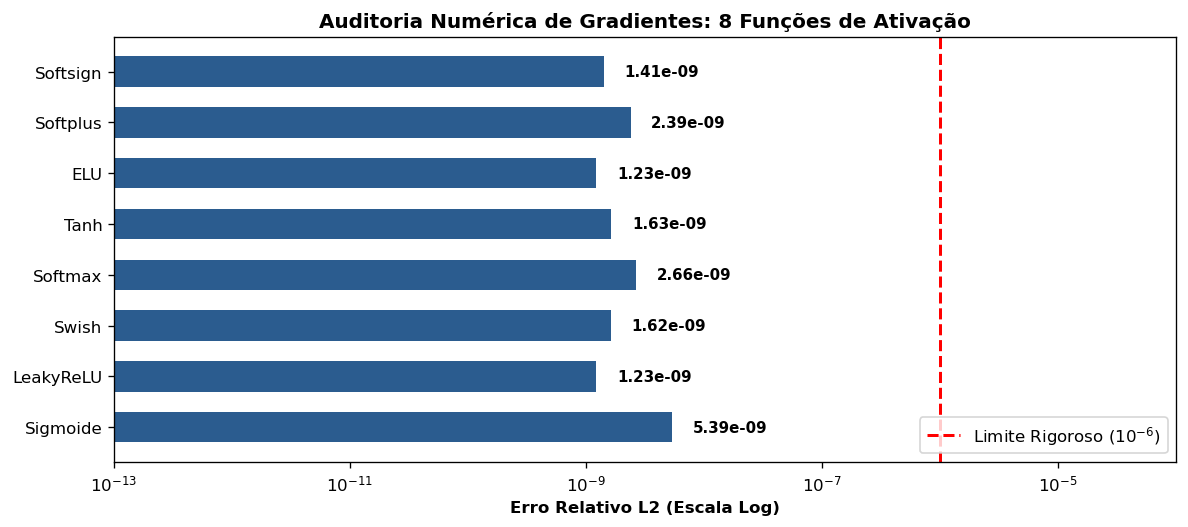

In [4]:
# Auditoria de gradientes de todas as 8 ativações
rng = np.random.RandomState(42)
entradas_teste = rng.uniform(0.1, 2.0, size=(4, 5))
grad_saida_teste = rng.randn(4, 5)

ativacoes_lista = [
    ("Sigmoide", Sigmoide()),
    ("LeakyReLU", LeakyReLU(alpha=0.01)),
    ("Swish", Swish()),
    ("Softmax", Softmax()),
    ("Tanh", Tanh()),
    ("ELU", ELU(alpha=1.0)),
    ("Softplus", Softplus()),
    ("Softsign", Softsign()),
]

nomes_ativ = []
erros_ativ = []

for nome, ativ in ativacoes_lista:
    err = checar_gradiente_ativacao(ativ, entradas_teste.copy(), grad_saida_teste.copy(), epsilon=1e-7)
    nomes_ativ.append(nome)
    erros_ativ.append(err)

# Gráfico de barras horizontal dos erros relativos
fig, ax = plt.subplots(figsize=(10, 4.5))

cores_barras = ["#2b5c8f" if e < 1e-6 else "#d95f02" for e in erros_ativ]
barras = ax.barh(nomes_ativ, erros_ativ, color=cores_barras, height=0.6)

ax.axvline(1e-6, color="red", linestyle="--", linewidth=1.8, label="Limite Rigoroso ($10^{-6}$)")
ax.set_xscale("log")
ax.set_xlabel("Erro Relativo L2 (Escala Log)", fontweight="bold")
ax.set_title("Auditoria Numérica de Gradientes: 8 Funções de Ativação", fontweight="bold")
ax.set_xlim(1e-13, 1e-4)
ax.legend(loc="lower right")

for b, err in zip(barras, erros_ativ):
    ax.annotate(f"{err:.2e}", (err * 1.5, b.get_y() + b.get_height() / 2),
                va="center", fontweight="bold", fontsize=9)

plt.tight_layout()
plt.show()

print("--- RELATÓRIO DE AUDITORIA DAS ATIVAÇÕES ---")
for nome, err in zip(nomes_ativ, erros_ativ):
    status = "APROVADO (< 1e-6)" if err < 1e-6 else "REPROVADO"
    print(f"{nome:12s} -> Erro Relativo: {err:.2e} | Status: {status}")


## 4. Auditoria da Camada Densa: Pesos ($W$), Vieses ($b$) e Entradas ($X$)

A camada `Densa` possui três componentes de derivada:
1. $\dfrac{\partial L}{\partial W} = X^T \cdot \delta$
2. $\dfrac{\partial L}{\partial b} = \sum_{i=1}^N \delta_{i, :}$
3. $\dfrac{\partial L}{\partial X} = \delta \cdot W^T$

Abaixo, auditamos simultaneamente os três componentes via `checar_gradiente_camada_densa`.


--- RESULTADOS DA CAMADA DENSA ---
Componente 'pesos': Erro = 1.28e-09 -> PERFEITO
Componente 'vieses': Erro = 2.02e-08 -> PERFEITO
Componente 'entradas': Erro = 1.42e-09 -> PERFEITO


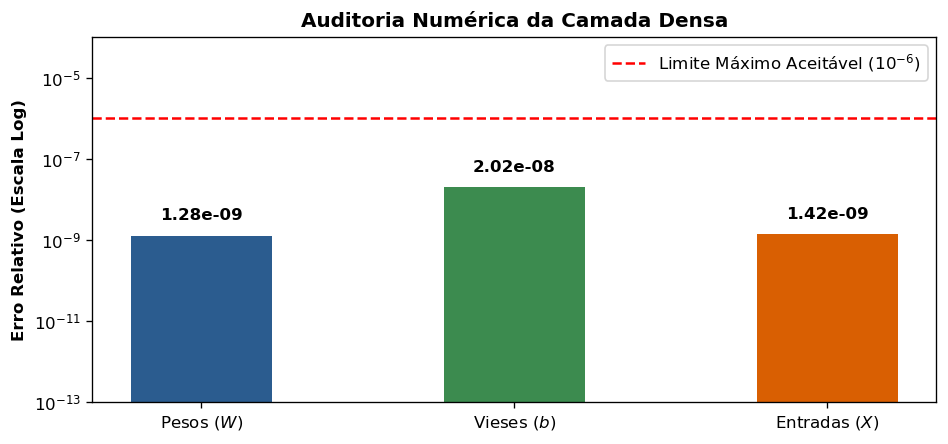

In [5]:
# Auditoria numérica da Camada Densa
rng_densa = np.random.RandomState(99)
camada_densa = Densa(dimensao_entrada=4, dimensao_saida=3, gerador_aleatorio=rng_densa)

X_densa = rng_densa.randn(5, 4)
grad_saida_densa = rng_densa.randn(5, 3)

erros_densa = checar_gradiente_camada_densa(camada_densa, X_densa, grad_saida_densa, epsilon=1e-7)

fig, ax = plt.subplots(figsize=(8, 3.8))

chaves = ["Pesos ($W$)", "Vieses ($b$)", "Entradas ($X$)"]
valores = [erros_densa["pesos"], erros_densa["vieses"], erros_densa["entradas"]]

barras = ax.bar(chaves, valores, color=["#2b5c8f", "#3c8b4f", "#d95f02"], width=0.45)
ax.axhline(1e-6, color="red", linestyle="--", linewidth=1.5, label="Limite Máximo Aceitável ($10^{-6}$)")
ax.set_yscale("log")
ax.set_ylabel("Erro Relativo (Escala Log)", fontweight="bold")
ax.set_title("Auditoria Numérica da Camada Densa", fontweight="bold")
ax.set_ylim(1e-13, 1e-4)
ax.legend(loc="upper right")

for b, val in zip(barras, valores):
    ax.annotate(f"{val:.2e}", (b.get_x() + b.get_width() / 2, val * 2),
                ha="center", va="bottom", fontweight="bold", fontsize=10)

plt.tight_layout()
plt.show()

print("--- RESULTADOS DA CAMADA DENSA ---")
for k, v in erros_densa.items():
    print(f"Componente '{k}': Erro = {v:.2e} -> {'PERFEITO' if v < 1e-6 else 'FALHA'}")


## 5. Auditoria Ponta a Ponta de Redes Profundas (`RedeNeural`)

A função `checar_gradiente_rede` percorre todas as camadas densas da rede, perturbando cada sinapse individualmente e recalculando o custo escalar completo $L(y, \text{Rede}(X))$.

Abaixo, testamos uma rede profunda de 3 camadas com ativações não-lineares e custo `MSE`.


In [6]:
# Construção de rede profunda para checagem ponta a ponta
rng_net = np.random.RandomState(42)
rede_profunda = RedeNeural(semente_aleatoria=42)

rede_profunda.adicionar(Densa(4, 6, gerador_aleatorio=rng_net))
rede_profunda.adicionar(Swish())
rede_profunda.adicionar(Densa(6, 4, gerador_aleatorio=rng_net))
rede_profunda.adicionar(LeakyReLU(alpha=0.01))
rede_profunda.adicionar(Densa(4, 2, gerador_aleatorio=rng_net))
rede_profunda.compilar(MSE())

X_net = rng_net.randn(5, 4)
y_net = rng_net.randn(5, 2)

relatorio_rede = checar_gradiente_rede(rede_profunda, X_net, y_net, epsilon=1e-7, tolerancia=1e-6)

print("--- AUDITORIA PONTA A PONTA DA REDE PROFUNDA ---")
print(f"Status Global: {'APROVADO COM SUCESSO' if relatorio_rede['passou_tolerancia'] else 'REPROVADO'}")
print(f"Erro Relativo Máximo em toda a rede: {relatorio_rede['erro_relativo_maximo']:.2e}")

for c in relatorio_rede["camadas"]:
    idx = c["indice_camada"]
    print(f"Camada Densa {idx:02d} -> Erro Pesos (W): {c['erro_relativo_pesos']:.2e} | Erro Vieses (b): {c['erro_relativo_vieses']:.2e}")


--- AUDITORIA PONTA A PONTA DA REDE PROFUNDA ---
Status Global: APROVADO COM SUCESSO
Erro Relativo Máximo em toda a rede: 2.57e-08
Camada Densa 00 -> Erro Pesos (W): 2.70e-09 | Erro Vieses (b): 8.60e-09
Camada Densa 02 -> Erro Pesos (W): 2.50e-09 | Erro Vieses (b): 2.57e-08
Camada Densa 04 -> Erro Pesos (W): 3.21e-09 | Erro Vieses (b): 1.66e-08


## 6. Guia Prático para a Arguição Oral com o Professor

### P1: Qual a justificativa matemática para o uso de diferenças centradas em vez de unilaterais?
**Resposta:** A expansão de Taylor demonstra que a aproximação centrada $(f(x+\epsilon) - f(x-\epsilon))/(2\epsilon)$ cancela os termos pares da série, gerando um erro de truncamento de ordem quadrática $\mathcal{O}(\epsilon^2)$. Já a aproximação unilateral $(f(x+\epsilon) - f(x))/\epsilon$ mantém o termo de primeira ordem, tendo erro $\mathcal{O}(\epsilon)$. Para $\epsilon = 10^{-7}$, a diferença centrada alcança precisão teórica de $10^{-14}$, contra apenas $10^{-7}$ da unilateral.

### P2: O que causa a curva em 'V' na precisão do Gradient Checking ao variar $\epsilon$?
**Resposta:** Trata-se da competição entre dois fenômenos numéricos:
1. Para $\epsilon > 10^{-4}$, o **erro de truncamento** da aproximação linear domina.
2. Para $\epsilon < 10^{-10}$, ocorre o **cancelamento catastrófico**: a subtração de dois números quase idênticos em ponto flutuante IEEE 754 de 64 bits elimina os dígitos significativos da mantissa, e a divisão por $2\epsilon$ amplifica o ruído numérico. O mínimo dessa curva ocorre em $\epsilon \approx 10^{-7}$.

### P3: Por que não é viável usar Gradient Checking para treinar redes no lugar do Backpropagation?
**Resposta:** Devido à complexidade computacional. Para uma rede com $M$ parâmetros, o gradient checking requer $2M$ propagações diretas completas ($f(\theta + \epsilon)$ e $f(\theta - \epsilon)$ para cada peso). Em contrapartida, a retropropagação analítica computa os gradientes exatos de **todos** os $M$ parâmetros simultaneamente com **uma única ida e uma única volta**. O gradient checking serve exclusivamente como teste e auditoria analítica de código.

### P4: O que são 'kinks' e como eles podem gerar falsos alarmes no Gradient Checking?
**Resposta:** *Kinks* são pontos de descontinuidade na derivada de funções não-lineares, como $z = 0$ na `LeakyReLU` ou na `ReLU`. Se a perturbação $\epsilon$ cruzar o ponto anguloso ($z - \epsilon < 0 < z + \epsilon$), a diferença finita centrada calculará a média das derivadas dos dois regimes lineares, diferindo da derivada analítica unilateral. Para evitar falsos alarmes, as amostras de teste do gradient check devem ser ligeiramente afastadas dos pontos angulosos.
